# Methane plume classifier

Small CNN that labels a 32×32 Sentinel-5P methane patch as **plume** or **no plume**.

- **Data:** `backend/data/methane/` from `backend/scripts/build_dataset.py` (labels = SRON weekly detections)
- **Input:** 2 channels: CH4 enhancement (ppb above patch median) and valid-pixel mask
- **Split:** by date (train = oldest 70%, val = next 15%, test = newest 15%)
- **Output:** precision / recall / F1 on test, and `backend/models/methane_cnn.pt`

Setup: `backend\venv\Scripts\pip install torch scikit-learn ipykernel`

In [1]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, precision_recall_curve,
                             precision_recall_fscore_support, roc_auc_score)
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BACKEND = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "methane" / "metadata.csv").exists())
DATA = BACKEND / "data" / "methane"
MODEL_DIR = BACKEND / "models"
print(f"device: {DEVICE}   data: {DATA}")

device: cpu   data: c:\Users\drpri\VS_Projects\804_Hacks_26\backend\data\methane


## 1. Load the dataset

In [2]:
meta = pd.read_csv(DATA / "metadata.csv")
meta = meta[meta["path"].map(lambda p: (DATA / p).exists())].reset_index(drop=True)
meta["y"] = (meta["label"] == "plume").astype(np.float32)
meta.groupby(["split", "label"]).size().unstack()

label,no_plume,plume
split,,
test,356,290
train,1930,1251
val,461,265


In [3]:
X = np.stack([np.load(DATA / p) for p in meta["path"]]).astype(np.float32)  # (N, 2, 32, 32)
y = meta["y"].values
splits = {s: (meta["split"] == s).values for s in ["train", "val", "test"]}

# Scale the enhancement channel by the spread of valid train pixels, then clip outliers
train_pixels = X[splits["train"], 0][X[splits["train"], 1] > 0]
SCALE = float(np.percentile(np.abs(train_pixels), 95))
X[:, 0] = np.clip(X[:, 0] / SCALE, -3, 3)
print(f"{X.shape}   scale = {SCALE:.1f} ppb")

(4553, 2, 32, 32)   scale = 26.4 ppb


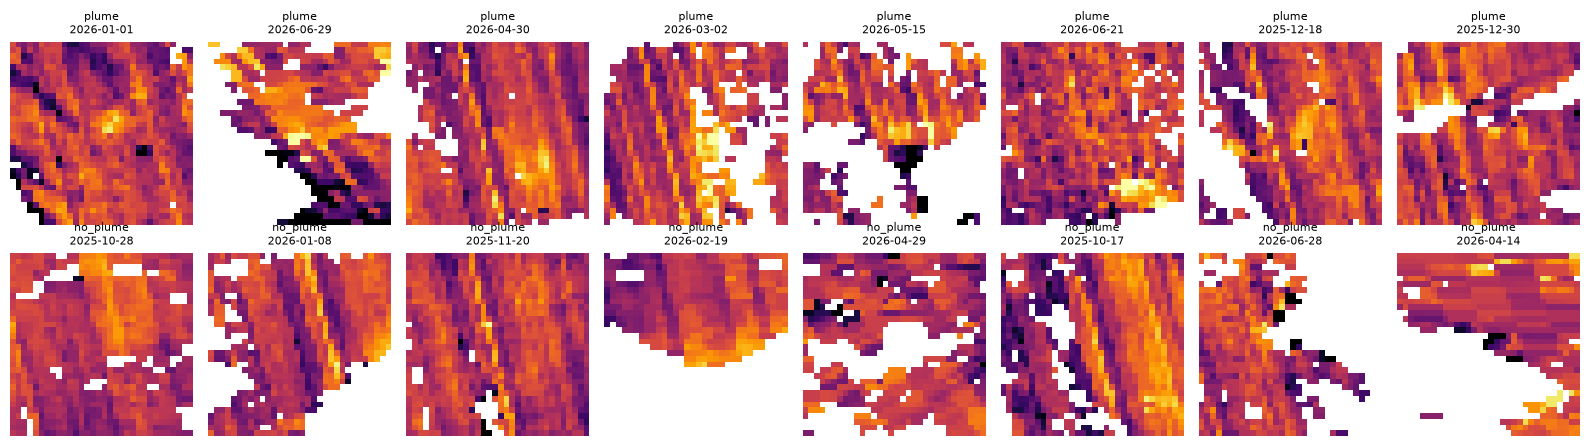

In [4]:
def show(ax, i, title):
    ax.imshow(np.where(X[i, 1] > 0, X[i, 0], np.nan), cmap="inferno", vmin=-1.5, vmax=1.5)
    ax.set_title(title, fontsize=8)
    ax.axis("off")


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for row, label in enumerate(["plume", "no_plume"]):
    idx = meta[(meta["label"] == label) & splits["train"]].sample(8, random_state=SEED).index
    for ax, i in zip(axes[row], idx):
        show(ax, i, f"{label}\n{meta.at[i, 'date']}")
plt.tight_layout()

## 2. Model

In [5]:
class Patches(Dataset):
    def __init__(self, X, y, augment=False):
        self.X, self.y, self.augment = torch.from_numpy(X), torch.from_numpy(y), augment

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.X[i]
        if self.augment:  # plumes have no preferred orientation
            x = torch.rot90(x, random.randint(0, 3), dims=(1, 2))
            if random.random() < 0.5:
                x = torch.flip(x, dims=(2,))
        return x, self.y[i]


loaders = {s: DataLoader(Patches(X[m], y[m], augment=(s == "train")), batch_size=64, shuffle=(s == "train"))
           for s, m in splits.items()}


class MethaneCNN(nn.Module):
    def __init__(self, in_ch=2, width=32, dropout=0.3):
        super().__init__()

        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                 nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                 nn.MaxPool2d(2))

        self.features = nn.Sequential(block(in_ch, width), block(width, width * 2), block(width * 2, width * 4))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(width * 4, 1))

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)


model = MethaneCNN().to(DEVICE)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

287,745 parameters


## 3. Train

Keeps the epoch with the best validation F1. `pos_weight` balances the extra no-plume patches.

In [6]:
EPOCHS = 30
n_pos = y[splits["train"]].sum()
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((len(y[splits["train"]]) - n_pos) / n_pos, device=DEVICE))
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)


def predict(loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(torch.sigmoid(model(xb.to(DEVICE))).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


history, best_f1, best_state = [], -1.0, None
for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for xb, yb in loaders["train"]:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        loss = loss_fn(model(xb), yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item() * len(yb)
    sched.step()

    p, t = predict(loaders["val"])
    prec, rec, f1, _ = precision_recall_fscore_support(t, p > 0.5, average="binary", zero_division=0)
    history.append({"epoch": epoch, "train_loss": total / len(loaders["train"].dataset),
                    "val_precision": prec, "val_recall": rec, "val_f1": f1})
    if f1 > best_f1:
        best_f1, best_state = f1, {k: v.detach().clone() for k, v in model.state_dict().items()}
    print(f"epoch {epoch:2d}  loss {history[-1]['train_loss']:.3f}  val P {prec:.2f}  R {rec:.2f}  F1 {f1:.3f}")

model.load_state_dict(best_state)
print(f"best val F1: {best_f1:.3f}")

epoch  1  loss 0.587  val P 0.82  R 0.51  F1 0.629
epoch  2  loss 0.498  val P 0.87  R 0.60  F1 0.713
epoch  3  loss 0.454  val P 0.73  R 0.80  F1 0.763
epoch  4  loss 0.429  val P 0.80  R 0.77  F1 0.785
epoch  5  loss 0.420  val P 0.69  R 0.91  F1 0.780
epoch  6  loss 0.406  val P 0.84  R 0.71  F1 0.768
epoch  7  loss 0.409  val P 0.78  R 0.85  F1 0.810
epoch  8  loss 0.375  val P 0.77  R 0.83  F1 0.797
epoch  9  loss 0.397  val P 0.73  R 0.88  F1 0.798
epoch 10  loss 0.372  val P 0.87  R 0.78  F1 0.819
epoch 11  loss 0.371  val P 0.81  R 0.83  F1 0.820
epoch 12  loss 0.353  val P 0.66  R 0.92  F1 0.771
epoch 13  loss 0.362  val P 0.77  R 0.85  F1 0.805
epoch 14  loss 0.341  val P 0.90  R 0.69  F1 0.780
epoch 15  loss 0.341  val P 0.91  R 0.71  F1 0.794
epoch 16  loss 0.332  val P 0.81  R 0.83  F1 0.817
epoch 17  loss 0.322  val P 0.79  R 0.85  F1 0.820
epoch 18  loss 0.319  val P 0.81  R 0.86  F1 0.836
epoch 19  loss 0.295  val P 0.75  R 0.90  F1 0.815
epoch 20  loss 0.310  val P 0.8

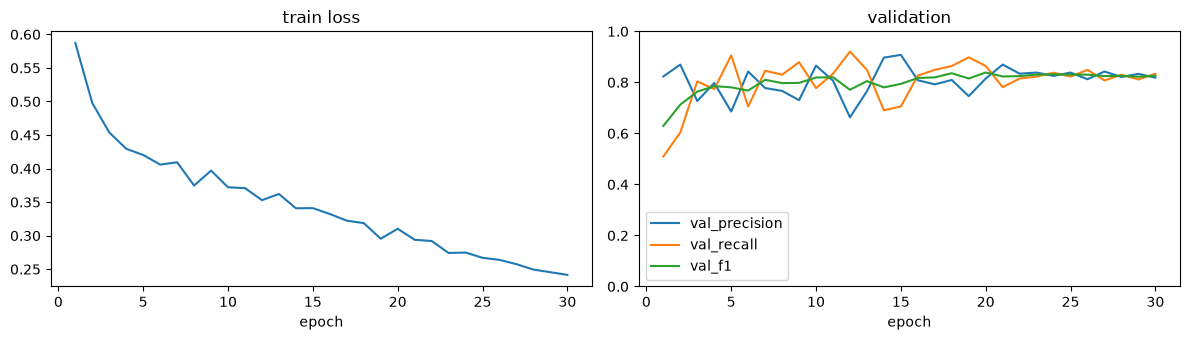

In [9]:
h = pd.DataFrame(history).set_index("epoch")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
h["train_loss"].plot(ax=a1, title="train loss")
h[["val_precision", "val_recall", "val_f1"]].plot(ax=a2, title="validation", ylim=(0, 1))
plt.tight_layout()
plt.show()

## 4. Pick the decision threshold on validation

In [10]:
p_val, t_val = predict(loaders["val"])
prec, rec, thr = precision_recall_curve(t_val, p_val)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
THRESHOLD = float(thr[f1s.argmax()])
print(f"best val F1 {f1s.max():.3f} at threshold {THRESHOLD:.2f}")

best val F1 0.842 at threshold 0.54


## 5. Test set (newest weeks, never seen in training)

{
  "precision": 0.886,
  "recall": 0.855,
  "f1": 0.87,
  "roc_auc": 0.944,
  "threshold": 0.54,
  "n_test": 646
}

False-positive rate by kind of no-plume patch:
kind
random       0.025
same_spot    0.141
Name: pred, dtype: float64


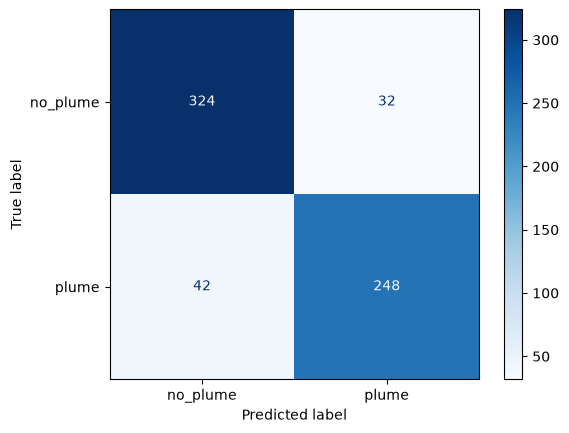

In [11]:
p_test, t_test = predict(loaders["test"])
pred = p_test >= THRESHOLD
prec, rec, f1, _ = precision_recall_fscore_support(t_test, pred, average="binary", zero_division=0)
test_metrics = {"precision": round(float(prec), 3), "recall": round(float(rec), 3), "f1": round(float(f1), 3),
                "roc_auc": round(float(roc_auc_score(t_test, p_test)), 3), "threshold": round(THRESHOLD, 3),
                "n_test": int(len(t_test))}
print(json.dumps(test_metrics, indent=2))

ConfusionMatrixDisplay(confusion_matrix(t_test, pred), display_labels=["no_plume", "plume"]).plot(cmap="Blues")

test_meta = meta[splits["test"]].assign(prob=p_test, pred=pred)
print("\nFalse-positive rate by kind of no-plume patch:")
print(test_meta[test_meta["label"] == "no_plume"].groupby("kind")["pred"].mean().round(3))

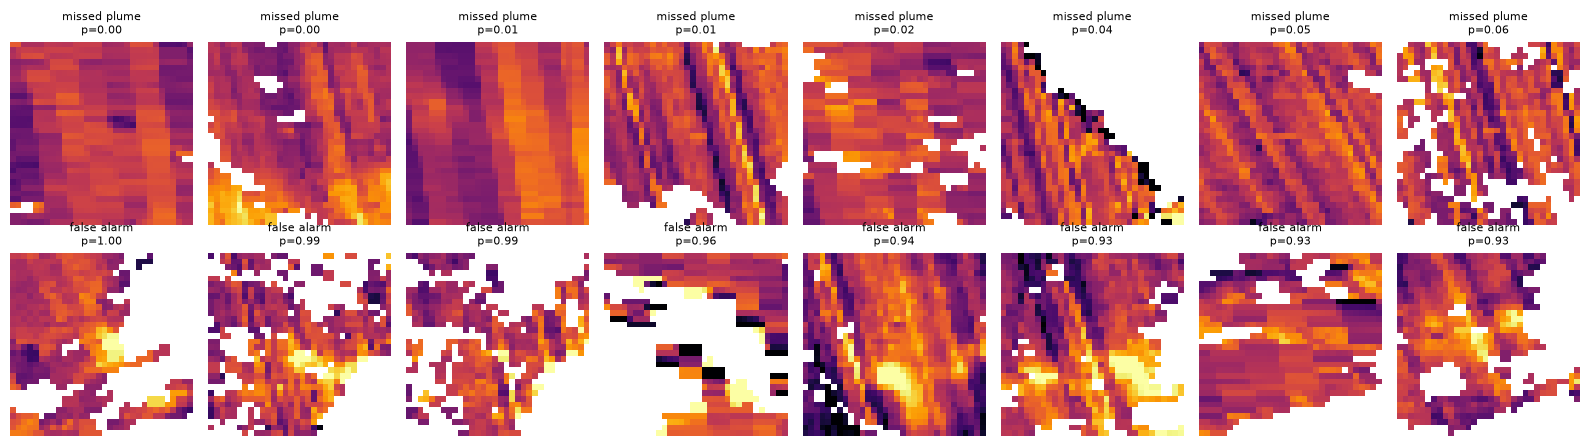

In [12]:
# Most confident mistakes
errors = test_meta[test_meta["pred"] != (test_meta["label"] == "plume")]
groups = [("missed plume", errors[errors["label"] == "plume"].sort_values("prob")),
          ("false alarm", errors[errors["label"] == "no_plume"].sort_values("prob", ascending=False))]
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for row, (name, df) in enumerate(groups):
    for ax in axes[row]:
        ax.axis("off")
    for ax, (i, r) in zip(axes[row], df.head(8).iterrows()):
        show(ax, i, f"{name}\np={r['prob']:.2f}")
plt.tight_layout()

## 6. Save

In [13]:
MODEL_DIR.mkdir(exist_ok=True)
torch.save({"state_dict": model.state_dict(), "scale_ppb": SCALE, "threshold": THRESHOLD,
            "patch": X.shape[-1], "metrics": test_metrics}, MODEL_DIR / "methane_cnn.pt")
(MODEL_DIR / "metrics.json").write_text(json.dumps(test_metrics, indent=2))
print(f"saved to {MODEL_DIR}")

saved to c:\Users\drpri\VS_Projects\804_Hacks_26\backend\models
